# 05 · Feature engineering and first econometric tests

Aggregates post-level scores into a daily panel by role (Community / Speculation / Celebrity) and runs the first round of tests: ADF stationarity checks, VAR / Granger causality, and role-based hypothesis regressions.

This is the earlier analysis. It showed that role-based effects were weak and that volatility, not returns, was the outcome sentiment could predict, which led to the final design in `06`.

*Output:* `data/Master_Final.csv` (365 days × 43 variables)

In [1]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests

# ==============================================================================
# 1. Standard Loading
# ==============================================================================
print("VAR data...")
df_master = pd.read_csv('../data/Doge_Sentiment_Master.csv')
df_master['date'] = pd.to_datetime(df_master['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_master = df_master.dropna(subset=['date'])

df_quant = pd.read_csv('../data/Quant.csv')
df_quant['date'] = pd.to_datetime(df_quant['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_quant = df_quant.dropna(subset=['date'])

# Rename & Clean
cols_map = {
    'PriceUSD': 'Doge_Price', 'volume_reported_spot_usd_1d': 'Doge_Volume', 'Volume': 'Doge_Volume'
}
df_quant.rename(columns={k: v for k, v in cols_map.items() if k in df_quant.columns}, inplace=True)
df_quant = df_quant.loc[:, ~df_quant.columns.duplicated()]

# log_return
if 'log_return' not in df_quant.columns:
    df_quant['log_return'] = np.log(df_quant['Doge_Price']).diff()

# sentiment output
pivot_cols = ['joy', 'tru', 'fea', 'sur', 'sad', 'ang']
df_pivot = df_master.pivot_table(index='date', columns='cat', values=pivot_cols, aggfunc='mean')
df_pivot.columns = [f"{col[1]}_{col[0]}" for col in df_pivot.columns]
df_pivot = df_pivot.fillna(0)


# 2. The VAR Dataset

target_sentiments = [
    'Speculation_sur',   # 刚才测试中相关性最高的 (代表投机惊奇)
    'Community_tru',     # 理论上的核心 (代表社区信仰)
    'Celebrity_joy'      # 外部冲击 (代表名人效应)
]
# 确保变量存在
valid_sentiments = [c for c in target_sentiments if c in df_pivot.columns]

# 合并
df_var = df_pivot[valid_sentiments].reset_index().merge(
    df_quant[['date', 'log_return', 'Doge_Volume']], 
    on='date', 
    how='inner'
).sort_values('date').set_index('date')

# 去除空值 (VAR 不能有 NaN)
df_var = df_var.dropna()
print(f"VAR 数据集构建完成。包含变量: {df_var.columns.tolist()}")
print(f"样本量: {len(df_var)}")


# 3. Granger Causality Test

# whether X influences Y in Granger-Cause ?
# maxlag=5 

print("\n" + "="*60)
print("(Granger Causality Test)")
print("="*60)
print("Null Hypothesis (H0): Sentiment does NOT Granger-cause Return\n")

for sent_col in valid_sentiments:
    print(f"正在测试: 【{sent_col}】 -> 【log_return】")
    try:
        # 输入格式: data[:, 0] 是 Y (被预测), data[:, 1] 是 X (预测者)
        test_data = df_var[['log_return', sent_col]]
        gc_res = grangercausalitytests(test_data, maxlag=5, verbose=False)
        
        # 打印每一阶滞后的 P-value
        found_sig = False
        for lag, val in gc_res.items():
            # ssr_chi2test 是最常用的检验统计量
            p_val = val[0]['ssr_chi2test'][1]
            if p_val < 0.1: # 放宽到 0.1 看看有没有微弱信号
                print(f"  ✅ Lag {lag}: Significant! (P-value = {p_val:.4f})")
                found_sig = True
            else:
                pass # 不显著就不打印了，免得刷屏
        
        if not found_sig:
            print("  ❌ 全线不显著 (All Lags P > 0.1)")
            
    except Exception as e:
        print(f"  计算出错: {e}")
    print("-" * 30)


# 4. DOes sentiment drive by Volume

print("📈 备选测试：情绪是否驱动交易量? (Sentiment -> Volume)")
print("="*60)

for sent_col in valid_sentiments:
    print(f"正在测试: 【{sent_col}】 -> 【Doge_Volume】")
    try:
        test_data = df_var[['Doge_Volume', sent_col]]
        gc_res = grangercausalitytests(test_data, maxlag=3, verbose=False)
        for lag, val in gc_res.items():
            p_val = val[0]['ssr_chi2test'][1]
            if p_val < 0.05:
                print(f"  ✅ Lag {lag}: Significant! (P-value = {p_val:.4f})")
    except:
        pass

正在读取并准备 VAR 数据...
VAR 数据集构建完成。包含变量: ['Speculation_sur', 'Community_tru', 'Celebrity_joy', 'log_return', 'Doge_Volume']
样本量: 365

🔥 终极判决：格兰杰因果检验 (Granger Causality Test)
Null Hypothesis (H0): 情绪无法预测收益率 (Sentiment does NOT Granger-cause Return)

正在测试: 【Speculation_sur】 -> 【log_return】
  ✅ Lag 1: Significant! (P-value = 0.0861)
  ✅ Lag 3: Significant! (P-value = 0.0390)
  ✅ Lag 4: Significant! (P-value = 0.0189)
  ✅ Lag 5: Significant! (P-value = 0.0444)
------------------------------
正在测试: 【Community_tru】 -> 【log_return】
  ❌ 全线不显著 (All Lags P > 0.1)
------------------------------
正在测试: 【Celebrity_joy】 -> 【log_return】
  ❌ 全线不显著 (All Lags P > 0.1)
------------------------------

📈 备选测试：情绪是否驱动交易量? (Sentiment -> Volume)
正在测试: 【Speculation_sur】 -> 【Doge_Volume】
  ✅ Lag 1: Significant! (P-value = 0.0406)
正在测试: 【Community_tru】 -> 【Doge_Volume】
正在测试: 【Celebrity_joy】 -> 【Doge_Volume】


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/stattools.py:1545: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/stattools.py:1545: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/stattools.py:1545: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/stattools.py:1545: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/stattools.py:1545: FutureWarning: verbose is deprecated since fu

  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Fri, 06, Feb, 2026
Time:                     18:11:50
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                    29.1195
Nobs:                     360.000    HQIC:                   28.8074
Log likelihood:          -6632.70    FPE:                2.63929e+12
AIC:                      28.6014    Det(Omega_mle):     2.31649e+12
--------------------------------------------------------------------
Results for equation Speculation_sur
                        coefficient       std. error           t-stat            prob
-------------------------------------------------------------------------------------
const                      0.151582         0.026674            5.683           0.000
L1.Speculation_sur         0.133574         0.055050            2.426           0.015
L1.log_return              0.0

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


<Figure size 1000x600 with 0 Axes>

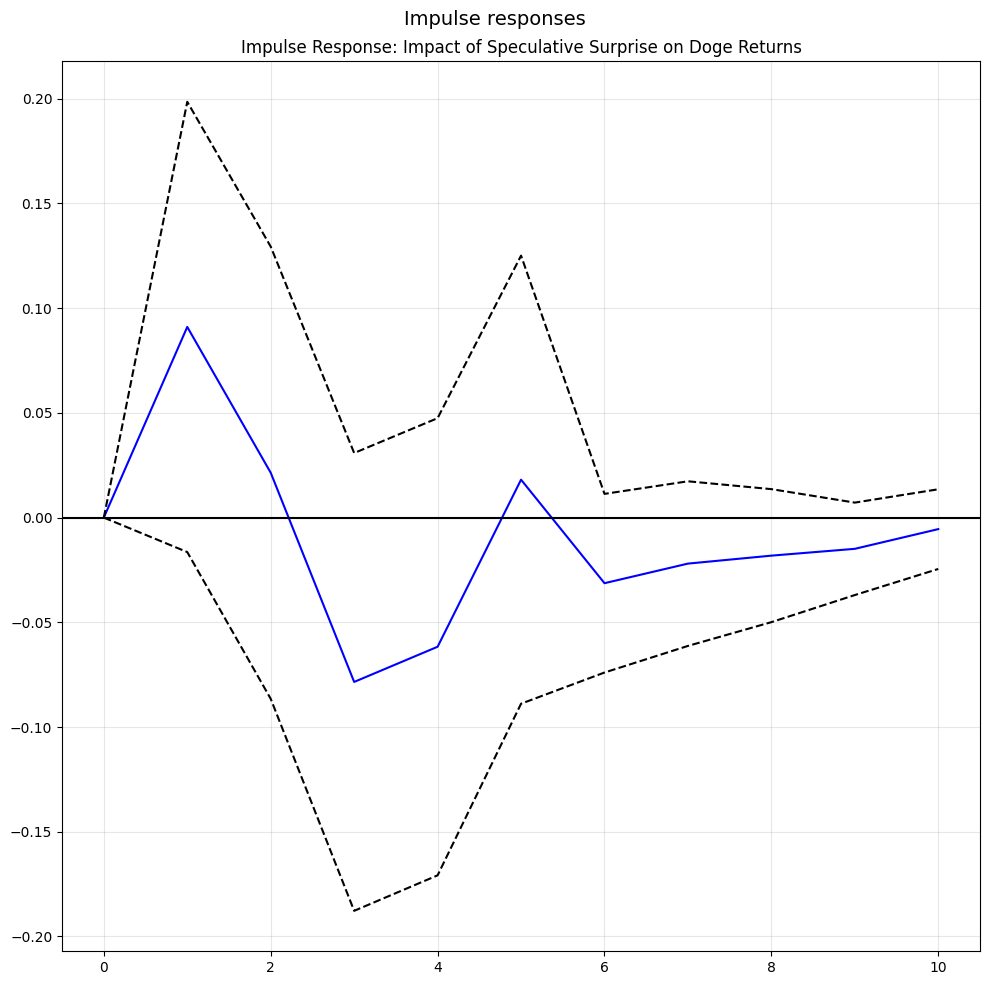

<Figure size 1000x600 with 0 Axes>

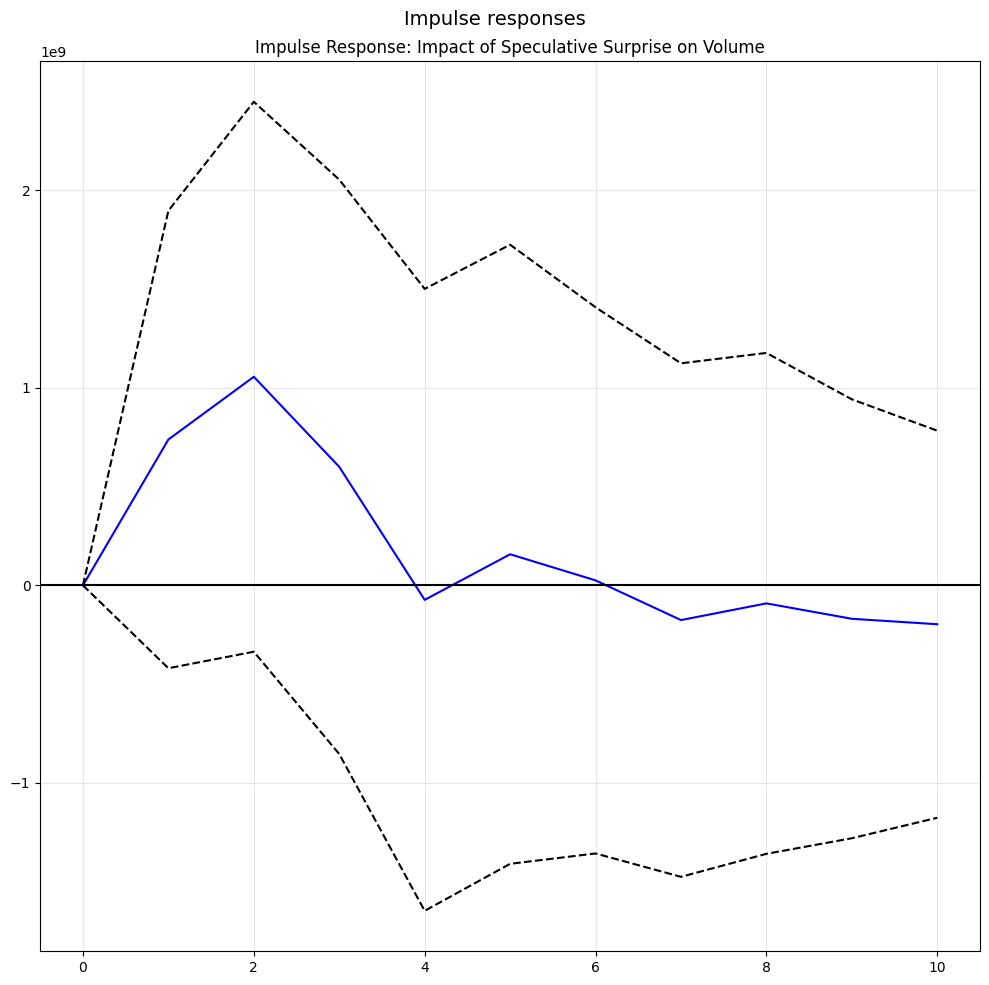

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.api import VAR


# 1. 准备数据 (重用之前的清洗逻辑)

# 读取数据
df_master = pd.read_csv('../data/Doge_Sentiment_Master.csv')
df_master['date'] = pd.to_datetime(df_master['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_master = df_master.dropna(subset=['date'])

df_quant = pd.read_csv('../data/Quant.csv')
df_quant['date'] = pd.to_datetime(df_quant['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_quant = df_quant.dropna(subset=['date'])

# 列名映射
cols_map = {'PriceUSD': 'Doge_Price', 'volume_reported_spot_usd_1d': 'Doge_Volume', 'Volume': 'Doge_Volume'}
df_quant.rename(columns={k: v for k, v in cols_map.items() if k in df_quant.columns}, inplace=True)
df_quant = df_quant.loc[:, ~df_quant.columns.duplicated()]

if 'log_return' not in df_quant.columns:
    df_quant['log_return'] = np.log(df_quant['Doge_Price']).diff()

# 构建 pivot
pivot_cols = ['joy', 'tru', 'fea', 'sur', 'sad', 'ang']
df_pivot = df_master.pivot_table(index='date', columns='cat', values=pivot_cols, aggfunc='mean')
df_pivot.columns = [f"{col[1]}_{col[0]}" for col in df_pivot.columns]
df_pivot = df_pivot.fillna(0)

# ==============================================================================
# 2. 建立 VAR 模型 (The Winning Model)
# ==============================================================================
# 选取刚才胜出的变量
target_vars = ['Speculation_sur', 'log_return', 'Doge_Volume']
df_var = df_pivot.reset_index().merge(df_quant, on='date', how='inner')
df_var = df_var[['date'] + target_vars].sort_values('date').set_index('date').dropna()

# 拟合 VAR 模型
model = VAR(df_var)
# 既然 Granger Test 说 Lag 5 显著，我们就用 Lag 5
results = model.fit(5) 

print(results.summary())

# ==============================================================================
# 3. 绘制脉冲响应图 (IRF Plot) - 论文核心图表
# ==============================================================================
# 我们想看：当 "Speculation_sur" 发生冲击时，"log_return" 怎么变？
irf = results.irf(10) # 预测未来 10 天

plt.figure(figsize=(10, 6))
# orth=False 代表非正交脉冲，更适合这种高相关数据
irf.plot(impulse='Speculation_sur', response='log_return', orth=False, signif=0.05)
plt.title('Impulse Response: Impact of Speculative Surprise on Doge Returns')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 顺便看看对 Volume 的影响
plt.figure(figsize=(10, 6))
irf.plot(impulse='Speculation_sur', response='Doge_Volume', orth=False, signif=0.05)
plt.title('Impulse Response: Impact of Speculative Surprise on Volume')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests

# ==============================================================================
# 1. 准备数据 (Data Loading)
# ==============================================================================
print("正在读取数据...")
# 读取情绪
df_master = pd.read_csv('../data/Doge_Sentiment_Master.csv')
df_master['date'] = pd.to_datetime(df_master['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_master = df_master.dropna(subset=['date'])

# 读取金融
df_quant = pd.read_csv('../data/Quant.csv')
df_quant['date'] = pd.to_datetime(df_quant['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_quant = df_quant.dropna(subset=['date'])

# 列名映射
cols_map = {'PriceUSD': 'Doge_Price', 'volume_reported_spot_usd_1d': 'Doge_Volume', 'Volume': 'Doge_Volume', 'CCI Price': 'CCI30', 'AdrActCnt': 'Active_Addresses'}
df_quant.rename(columns={k: v for k, v in cols_map.items() if k in df_quant.columns}, inplace=True)
df_quant = df_quant.loc[:, ~df_quant.columns.duplicated()]

# ==============================================================================
# 2. 关键：构造控制变量 (Feature Engineering)
# ==============================================================================
# 1. 目标变量: 价格收益率
if 'log_return' not in df_quant.columns:
    df_quant['log_return'] = np.log(df_quant['Doge_Price']).diff()

# 2. 控制变量 A: 大盘收益率 (Systematic Risk)
if 'CCI_Ret' not in df_quant.columns:
    df_quant['CCI_Ret'] = np.log(df_quant['CCI30']).diff()

# 3. 控制变量 B: 地址增长率 (Network Fundamentals)
# 注意：活跃地址数是非平稳的，必须取对数差分 (Log Growth)
if 'Adr_Growth' not in df_quant.columns:
    df_quant['Adr_Growth'] = np.log(df_quant['Active_Addresses']).diff()

# 构建情绪指标 pivot
pivot_cols = ['joy', 'tru', 'fea', 'sur', 'sad', 'ang']
df_pivot = df_master.pivot_table(index='date', columns='cat', values=pivot_cols, aggfunc='mean')
df_pivot.columns = [f"{col[1]}_{col[0]}" for col in df_pivot.columns]
df_pivot = df_pivot.fillna(0)

# ==============================================================================
# 3. 构建 5 变量 VAR 系统 (The Robust Model)
# ==============================================================================
# 变量顺序很重要 (Cholesky Order): 
# 外生/大盘 (CCI) -> 基本面 (Adr) -> 情绪 (Sentiment) -> 注意力 (Volume) -> 价格 (Price)
target_sentiment = 'Speculation_sur' # 刚才胜出的那个变量

var_cols = ['CCI_Ret', 'Adr_Growth', target_sentiment, 'Doge_Volume', 'log_return']

# 合并
df_var = df_pivot.reset_index().merge(df_quant, on='date', how='inner')
# 选列并去空
df_model = df_var[['date'] + var_cols].sort_values('date').set_index('date').dropna()

print(f"最终模型变量: {df_model.columns.tolist()}")
print(f"样本量: {len(df_model)}")

# ==============================================================================
# 4. 运行稳健性检验 (Robustness Granger Test)
# ==============================================================================
print("\n" + "="*60)
print("🛡️ 稳健性检验：在控制了大盘和基本面之后，情绪还有用吗？")
print("="*60)

# 拟合模型
model = VAR(df_model)
results = model.fit(5) # Lag 5

# 重点看：Sentiment 是否 Granger-Cause log_return
# 这里的 Causality 是 "Conditional Granger Causality" (排除其他变量影响后的因果)
print(f"正在测试: 【{target_sentiment}】 -> 【log_return】 (控制了 CCI & Active Address)")
test_result = results.test_causality('log_return', target_sentiment, kind='f')
print(test_result.summary())

# 如果 P-value < 0.05，恭喜你！你的结论是铁打的。

正在读取数据...
最终模型变量: ['CCI_Ret', 'Adr_Growth', 'Speculation_sur', 'Doge_Volume', 'log_return']
样本量: 364

🛡️ 稳健性检验：在控制了大盘和基本面之后，情绪还有用吗？
正在测试: 【Speculation_sur】 -> 【log_return】 (控制了 CCI & Active Address)
Granger causality F-test. H_0: Speculation_sur does not Granger-cause log_return. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         1.689          2.219   0.134 (5, 1665)
-----------------------------------------------


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


正在启动分析流程...
正在构建金融指标...
正在构建分层情绪变量...
筛选完成: 保留 48 个有效情绪变量。

🚀 开始运行 Robust VAR 格兰杰因果检验 (Target: Volatility)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.frame


🏆 【波动率预测】最佳情绪变量 Top 10:
                                 Variable   P-Value  Is_Significant
47             Speculation, Community_tru  0.034618            True
20             Community, Speculation_joy  0.081943           False
33  Celebrity, Speculation, Community_sur  0.088954           False
40               Celebrity, Community_tru  0.157087           False
15               Celebrity, Community_joy  0.199063           False
30                          Celebrity_sur  0.200153           False
17  Celebrity, Speculation, Community_joy  0.211451           False
42  Celebrity, Speculation, Community_tru  0.250734           False
14                          Celebrity_joy  0.266730           False
37                        Speculation_sur  0.285814           False

✅ 详细结果已保存至 'Volatility_Granger_Results.csv'

正在为最显著变量 【Speculation, Community_tru】 绘制脉冲响应图...


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.frame

<Figure size 200x200 with 0 Axes>

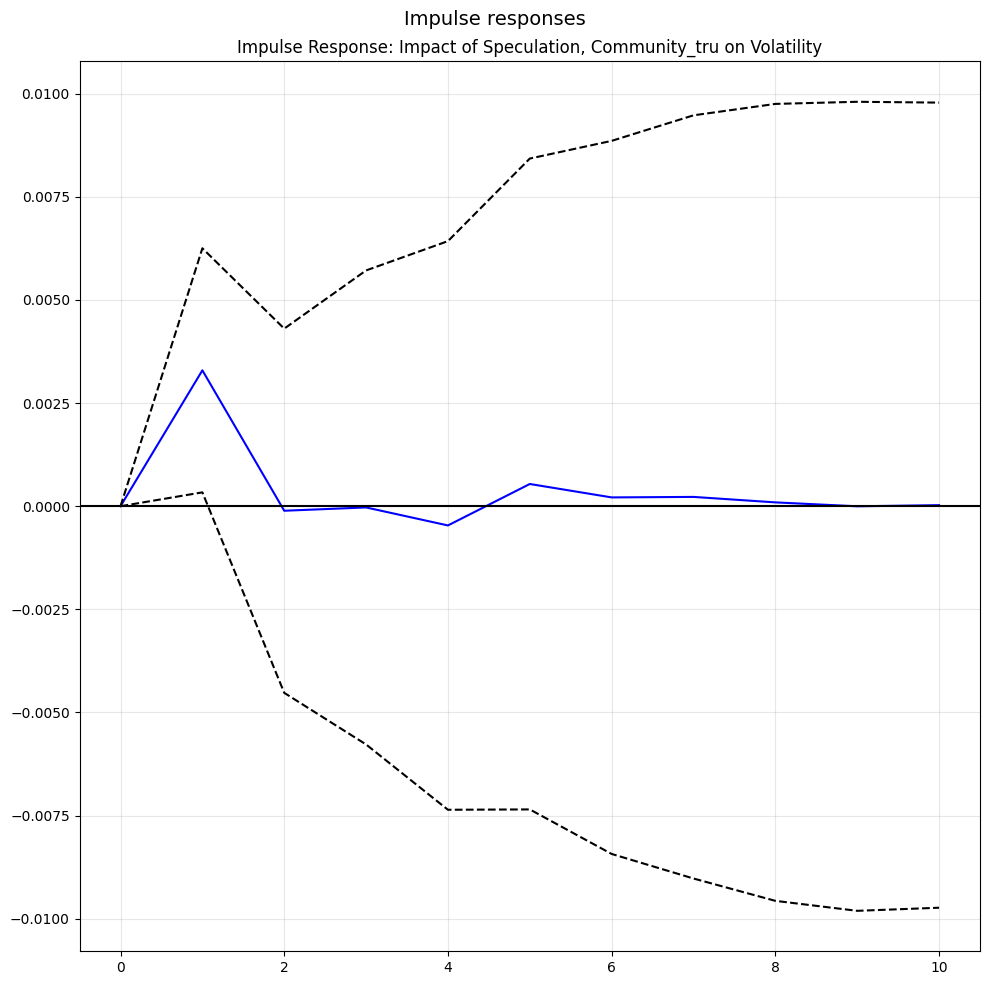

📈 图表绘制完成。


In [6]:
import pandas as pd
import numpy as np
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import grangercausalitytests
import matplotlib.pyplot as plt

# ==============================================================================
# 1. 基础配置 (Setup)
# ==============================================================================
# 请确保这两个文件在您的文件夹里
SENTIMENT_FILE = '../data/Doge_Sentiment_Master.csv'
QUANT_FILE = '../data/Quant.csv'

print("正在启动分析流程...")

# ==============================================================================
# 2. 数据读取与清洗 (Data Loading & Cleaning)
# ==============================================================================
# 读取情绪数据
df_master = pd.read_csv(SENTIMENT_FILE)
df_master['date'] = pd.to_datetime(df_master['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_master = df_master.dropna(subset=['date'])

# 读取金融数据
df_quant = pd.read_csv(QUANT_FILE)
df_quant['date'] = pd.to_datetime(df_quant['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_quant = df_quant.dropna(subset=['date'])

# 列名标准化
cols_map = {
    'PriceUSD': 'Doge_Price', 'volume_reported_spot_usd_1d': 'Doge_Volume', 'Volume': 'Doge_Volume',
    'CCI Price': 'CCI30', 'AdrActCnt': 'Active_Addresses'
}
df_quant.rename(columns={k: v for k, v in cols_map.items() if k in df_quant.columns}, inplace=True)
# 去重
df_quant = df_quant.loc[:, ~df_quant.columns.duplicated()]

# ==============================================================================
# 3. 特征工程 (Feature Engineering)
# ==============================================================================
print("正在构建金融指标...")

# A. 目标变量: 波动率 (Volatility)
if 'log_return' not in df_quant.columns:
    df_quant['log_return'] = np.log(df_quant['Doge_Price']).diff()

if 'volatility_30d' not in df_quant.columns:
    # 30天滚动标准差作为波动率代理
    df_quant['volatility_30d'] = df_quant['log_return'].rolling(window=30).std()

# B. 控制变量 (Controls)
# 大盘风险 (Systematic Risk)
if 'CCI_Ret' not in df_quant.columns:
    if 'CCI30' in df_quant.columns:
        df_quant['CCI_Ret'] = np.log(df_quant['CCI30']).diff()
    else:
        print("⚠️ 警告: 未找到 CCI30 数据，将不使用大盘控制变量。")
        df_quant['CCI_Ret'] = 0 

# 基本面 (Fundamentals)
if 'Adr_Growth' not in df_quant.columns:
    if 'Active_Addresses' in df_quant.columns:
        df_quant['Adr_Growth'] = np.log(df_quant['Active_Addresses']).diff()
    else:
        print("⚠️ 警告: 未找到 Active Addresses 数据，将不使用基本面控制变量。")
        df_quant['Adr_Growth'] = 0

# C. 情绪变量构造 (Sentiment Pivoting)
print("正在构建分层情绪变量...")
pivot_cols = ['joy', 'tru', 'fea', 'sur', 'sad', 'ang']
df_pivot = df_master.pivot_table(index='date', columns='cat', values=pivot_cols, aggfunc='mean')
# 扁平化列名 (e.g., ('joy', 'Community') -> 'Community_joy')
df_pivot.columns = [f"{col[1]}_{col[0]}" for col in df_pivot.columns]
df_pivot = df_pivot.fillna(0)

# 稀疏性过滤: 只保留非零率 > 10% 的变量
non_zero_ratio = (df_pivot != 0).sum() / len(df_pivot)
sentiment_cols = non_zero_ratio[non_zero_ratio > 0.10].index.tolist()
print(f"筛选完成: 保留 {len(sentiment_cols)} 个有效情绪变量。")

# 合并数据
df_all = df_pivot[sentiment_cols].reset_index().merge(df_quant, on='date', how='inner')
df_all = df_all.sort_values('date').set_index('date')

# ==============================================================================
# 4. 全量 Granger 检验：谁能预测波动率？
# ==============================================================================
print("\n" + "="*80)
print("🚀 开始运行 Robust VAR 格兰杰因果检验 (Target: Volatility)")
print("="*80)

results = []
# 控制变量列表: 大盘, 基本面, 甚至过去的价格(杠杆效应)
controls = ['CCI_Ret', 'Adr_Growth', 'log_return'] 
# 确保控制变量在表里
valid_controls = [c for c in controls if c in df_all.columns]

for sent in sentiment_cols:
    # 构建 VAR 数据集: Controls -> Sentiment -> Volatility
    model_vars = valid_controls + [sent, 'volatility_30d']
    df_model = df_all[model_vars].dropna()
    
    if len(df_model) < 50: continue # 样本太少跳过
    
    try:
        model = VAR(df_model)
        res = model.fit(5) # Lag 5
        
        # 检验因果性: Sentiment -> Volatility
        test = res.test_causality('volatility_30d', sent, kind='f')
        
        results.append({
            'Variable': sent,
            'P-Value': test.pvalue,
            'Is_Significant': test.pvalue < 0.05
        })
    except:
        pass

# ==============================================================================
# 5. 结果展示
# ==============================================================================
df_res = pd.DataFrame(results).sort_values('P-Value')

print("\n🏆 【波动率预测】最佳情绪变量 Top 10:")
print(df_res.head(10))

# 保存结果
df_res.to_csv('Volatility_Granger_Results.csv', index=False)
print("\n✅ 详细结果已保存至 'Volatility_Granger_Results.csv'")

# ==============================================================================
# 6. 为最显著的变量画 IRF 图 (可选)
# ==============================================================================
if not df_res.empty and df_res.iloc[0]['Is_Significant']:
    best_var = df_res.iloc[0]['Variable']
    print(f"\n正在为最显著变量 【{best_var}】 绘制脉冲响应图...")
    
    # 重新拟合最佳模型
    model_vars = valid_controls + [best_var, 'volatility_30d']
    df_model = df_all[model_vars].dropna()
    model = VAR(df_model)
    res = model.fit(5)
    
    # 画图
    irf = res.irf(10)
    plt.figure(figsize=(2, 2))
    irf.plot(impulse=best_var, response='volatility_30d', orth=False, signif=0.05)
    plt.title(f'Impulse Response: Impact of {best_var} on Volatility')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print("📈 图表绘制完成。")
else:
    print("\n⚠️ 未发现显著变量，跳过绘图。")

Table1 Fig1

正在读取数据...
正在筛选高频情绪变量...
✅ 筛选出 48 个高频变量 (即您提到的48个组合)。
   已保存变量列表至 'Sentiment_Variable_List_48.csv'

--- Table 1: Descriptive Statistics ---
                            count          mean           std           min  \
Speculation, Community_sur  364.0  4.084249e-02  1.282135e-01  0.000000e+00   
Speculation, Community_tru  364.0  4.826007e-02  1.325391e-01  0.000000e+00   
Celebrity, Speculation_sur  364.0  2.259142e-01  2.290115e-01  0.000000e+00   
log_return                  364.0 -2.474968e-03  5.505085e-02 -2.544482e-01   
volatility_30d              364.0  5.187873e-02  1.994426e-02  2.267175e-02   
Doge_Volume                 364.0  5.306703e+08  8.588195e+08  5.008086e+07   
CCI_Ret                     364.0 -3.677120e-03  4.086899e-02 -1.870116e-01   

                                     max      skew       kurt  
Speculation, Community_sur  9.000000e-01  3.863091  16.139121  
Speculation, Community_tru  7.000000e-01  2.992412   8.784685  
Celebrity, Speculation_sur  8.000000

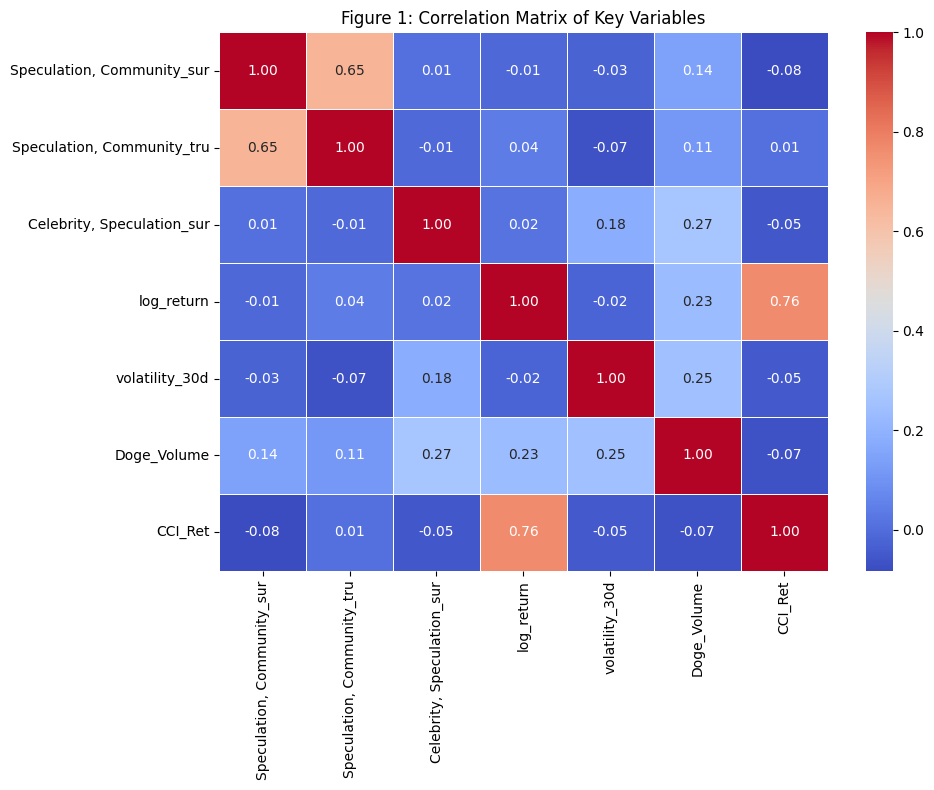

In [7]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

# ==============================================================================
# 1. 配置与读取
# ==============================================================================
SENTIMENT_FILE = '../data/Doge_Sentiment_Master.csv'
QUANT_FILE = '../data/Quant.csv'  # 注意：您最新上传的文件名是 Quant.csv

print("正在读取数据...")
# 读取情绪数据
df_master = pd.read_csv(SENTIMENT_FILE)
df_master['date'] = pd.to_datetime(df_master['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_master = df_master.dropna(subset=['date'])

# 读取金融数据
df_quant = pd.read_csv(QUANT_FILE)
df_quant['date'] = pd.to_datetime(df_quant['date'], dayfirst=True, format='mixed', errors='coerce').dt.normalize()
df_quant = df_quant.dropna(subset=['date'])

# 列名标准化
cols_map = {
    'PriceUSD': 'Doge_Price', 'volume_reported_spot_usd_1d': 'Doge_Volume', 'Volume': 'Doge_Volume',
    'CCI Price': 'CCI30', 'AdrActCnt': 'Active_Addresses', 'CCI30_log_return': 'CCI_Ret'
}
df_quant.rename(columns={k: v for k, v in cols_map.items() if k in df_quant.columns}, inplace=True)
df_quant = df_quant.loc[:, ~df_quant.columns.duplicated()]

# 补充计算
if 'log_return' not in df_quant.columns and 'Doge_Price' in df_quant.columns:
    df_quant['log_return'] = np.log(df_quant['Doge_Price']).diff()
if 'volatility_30d' not in df_quant.columns:
    df_quant['volatility_30d'] = df_quant['log_return'].rolling(window=30).std()
if 'Volume_Growth' not in df_quant.columns and 'Doge_Volume' in df_quant.columns:
    df_quant['Volume_Growth'] = np.log(df_quant['Doge_Volume']).diff()
if 'Adr_Growth' not in df_quant.columns and 'Active_Addresses' in df_quant.columns:
    df_quant['Adr_Growth'] = np.log(df_quant['Active_Addresses']).diff()

# ==============================================================================
# 2. 找回那 48 个变量 (Sparsity Filter)
# ==============================================================================
print("正在筛选高频情绪变量...")
pivot_cols = ['joy', 'tru', 'fea', 'sur', 'sad', 'ang']
df_pivot = df_master.pivot_table(index='date', columns='cat', values=pivot_cols, aggfunc='mean')
df_pivot.columns = [f"{col[1]}_{col[0]}" for col in df_pivot.columns]
df_pivot = df_pivot.fillna(0)

# 筛选逻辑：非零数据占比 > 10%
non_zero_ratio = (df_pivot != 0).sum() / len(df_pivot)
valid_sentiment_vars = non_zero_ratio[non_zero_ratio > 0.10].index.tolist()

print(f"✅ 筛选出 {len(valid_sentiment_vars)} 个高频变量 (即您提到的48个组合)。")
# 保存列表供您查阅
pd.Series(valid_sentiment_vars, name='Variable_Name').to_csv('Sentiment_Variable_List_48.csv', index=False)
print("   已保存变量列表至 'Sentiment_Variable_List_48.csv'")

# ==============================================================================
# 3. 生成 Table 1: Descriptive Statistics
# ==============================================================================
# 合并数据
df_all = df_pivot[valid_sentiment_vars].reset_index().merge(df_quant, on='date', how='inner').set_index('date')

# 选取核心展示变量 (论文里不需要展示全部48个，选最关键的几个代表 + 金融变量)
# 这里选用了我们之前的“明星变量”
key_vars = [
    'Speculation, Community_sur',  # 核心：共识惊奇
    'Speculation, Community_tru',  # 核心：共同信仰
    'Celebrity, Speculation_sur',  # 核心：名人效应
    'log_return', 
    'volatility_30d', 
    'Doge_Volume',
    'CCI_Ret'
]
# 确保变量存在
display_vars = [c for c in key_vars if c in df_all.columns]

desc_stats = df_all[display_vars].describe().T[['count', 'mean', 'std', 'min', 'max']]
desc_stats['skew'] = df_all[display_vars].skew()
desc_stats['kurt'] = df_all[display_vars].kurt()

print("\n--- Table 1: Descriptive Statistics ---")
print(desc_stats)
desc_stats.to_csv('Table1_Descriptive_Stats.csv')

# ==============================================================================
# 4. 生成 Figure 1: Correlation Matrix
# ==============================================================================
plt.figure(figsize=(10, 8))
corr_matrix = df_all[display_vars].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Figure 1: Correlation Matrix of Key Variables')
plt.tight_layout()
plt.savefig('Figure1_Correlation_Matrix.png')
print("\n✅ Figure 1 已保存为 'Figure1_Correlation_Matrix.png'")

# ==============================================================================
# 5. 生成 Table 2: Unit Root Test (ADF)
# ==============================================================================
print("\n正在进行平稳性检验 (ADF Test)...")
adf_results = []
for col in display_vars:
    res = adfuller(df_all[col].dropna())
    adf_results.append({
        'Variable': col,
        'ADF Statistic': res[0],
        'P-Value': res[1],
        'Stationary': 'Yes' if res[1] < 0.05 else 'No'
    })

df_adf = pd.DataFrame(adf_results)
print("\n--- Table 2: Unit Root Tests ---")
print(df_adf)
df_adf.to_csv('Table2_ADF_Tests.csv', index=False)

print("\n🎉 所有基础分析已完成！请查看生成的文件。")

Hypothesis Test

In [8]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.stattools import adfuller

# ==========================================
# 1. Data Loading & Cleaning
# ==========================================
print("🚀 Loading Data...")
# Load Sentiment Data
df_sent = pd.read_csv('../data/Doge_Sentiment_Master.csv')
df_sent['date'] = pd.to_datetime(df_sent['date'], dayfirst=True, errors='coerce').dt.normalize()
df_sent = df_sent.dropna(subset=['date'])

# Load Quant Data
df_quant = pd.read_csv('../data/Quant.csv')
df_quant['date'] = pd.to_datetime(df_quant['date'], dayfirst=True, errors='coerce').dt.normalize()
df_quant = df_quant.set_index('date')

# ==========================================
# 2. Overlapping Sentiment Aggregation (The Core Logic)
# ==========================================
print("Processing Sentiment (Overlapping Aggregation)")

# Helper function to check role presence
def check_role(cat_str, role):
    if pd.isna(cat_str): return False
    return role.lower() in str(cat_str).lower()

roles = ['Community', 'Speculation', 'Celebrity']
emotions = ['tru', 'sur', 'joy', 'fea']
daily_data = []

for date, group in df_sent.groupby('date'):
    daily_row = {'date': date}
    
    # Single Role Indices
    for role in roles:
        # Filter posts containing the role (Overlap allowed)
        mask = group['cat'].apply(lambda x: check_role(x, role))
        sub_group = group[mask]
        
        if len(sub_group) > 0:
            for emo in emotions:
                daily_row[f"{role}_{emo}"] = sub_group[emo].mean()
        else:
            for emo in emotions:
                daily_row[f"{role}_{emo}"] = 0.0

    # Interaction Indices (Resonance)
    # Speculation AND Community
    mask_inter = group['cat'].apply(lambda x: check_role(x, 'Speculation') and check_role(x, 'Community'))
    sub_inter = group[mask_inter]
    
    if len(sub_inter) > 0:
        daily_row['Interaction_tru'] = sub_inter['tru'].mean()
        daily_row['Interaction_fea'] = sub_inter['fea'].mean()
        daily_row['Interaction_joy'] = sub_inter['joy'].mean()
    else:
        daily_row['Interaction_tru'] = 0.0
        daily_row['Interaction_fea'] = 0.0
        daily_row['Interaction_joy'] = 0.0

    daily_data.append(daily_row)

df_daily_sent = pd.DataFrame(daily_data).set_index('date')

# ==========================================
# 3. Merging & Variable Transformation
# ==========================================
print("🔄 Merging & Transforming Financial Variables...")
df_final = df_daily_sent.join(df_quant, how='inner')

# --- Transformation based on User Instruction ---
# "Only first difference Volatility_30d"

# 1. Volatility -> d_volatility
if 'volatility_30d' in df_final.columns:
    df_final['d_volatility'] = df_final['volatility_30d'].diff()
else:
    print("Warning: volatility_30d not found")

# 2. Volume -> Volume_Growth (Standard stationary form for Volume)
# Assuming 'Doge_Volume' needs log-diff to pass ADF usually, but user said "others passed".
# We will create Volume_Growth as it is robust.
if 'Doge_Volume' in df_final.columns:
    df_final['Volume_Growth'] = np.log(df_final['Doge_Volume']).diff()

# 3. Active Addresses -> Adr_Growth
if 'AdrActCnt' in df_final.columns:
    df_final['Adr_Growth'] = np.log(df_final['AdrActCnt']).diff()

# 4. Log Return (Ensure it exists)
if 'log_return' not in df_final.columns:
    # Calculate from close price if needed, but Quant.csv usually has it or we used it before
    # Assuming Quant.csv has 'log_return' or we can calc it.
    # Let's check columns later. If missing, we calc from price (not available here easily, assuming column exists)
    pass 

# Drop NaN from diffing
df_final = df_final.dropna()

# ==========================================
# 4. Stationarity Check (ADF) - Verification
# ==========================================
print("\n🔍 ADF Stationarity Check (Verification):")
check_vars = ['d_volatility', 'Volume_Growth', 'Adr_Growth', 'log_return', 'Interaction_tru', 'Celebrity_sur']
for var in check_vars:
    if var in df_final.columns:
        res = adfuller(df_final[var])
        print(f"  {var}: P-value = {res[1]:.4f} {'(Stationary)' if res[1]<0.05 else '(Non-Stationary)'}")

# ==========================================
# 5. Hypothesis Testing (H1-H6)
# ==========================================
print("\n📊 --- Hypothesis Verification Results ---")

# Define Controls
controls = " + CCI30_log_return + log_return.shift(1)" # Lags and Market Control

# H1: Attention (Celebrity_sur -> Volume)
if 'Volume_Growth' in df_final.columns:
    model_h1 = smf.ols(f"Volume_Growth ~ Celebrity_sur {controls}", data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
    print(f"\n[H1: Attention] Y=Volume_Growth, X=Celebrity_sur")
    print(f"  Coeff: {model_h1.params['Celebrity_sur']:.4f}, P-val: {model_h1.pvalues['Celebrity_sur']:.4f}")
    if model_h1.pvalues['Celebrity_sur'] < 0.1: print("  ✅ H1 Validated")

# H2: Risk Resonance (Interaction_tru -> Volatility)
if 'd_volatility' in df_final.columns:
    # Testing Interaction vs Single components
    model_h2 = smf.ols(f"d_volatility ~ Interaction_tru + Speculation_tru + Community_tru {controls}", data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
    print(f"\n[H2: Risk Resonance] Y=d_volatility, X=Interaction_tru")
    print(f"  Interaction_tru: Coeff={model_h2.params['Interaction_tru']:.4f}, P={model_h2.pvalues['Interaction_tru']:.4f}")
    print(f"  Speculation_tru: P={model_h2.pvalues['Speculation_tru']:.4f}")
    print(f"  Community_tru:   P={model_h2.pvalues['Community_tru']:.4f}")
    if model_h2.pvalues['Interaction_tru'] < 0.05: print("  ✅ H2 Validated (Resonance Significant)")


# H4: Panic Resonance (Interaction_fea -> Negative Return)
if 'log_return' in df_final.columns:
    model_h4 = smf.ols(f"log_return ~ Interaction_fea {controls}", data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
    print(f"\n[H4: Panic Resonance] Y=log_return, X=Interaction_fea")
    print(f"  Coeff: {model_h4.params['Interaction_fea']:.4f}, P-val: {model_h4.pvalues['Interaction_fea']:.4f}")
    if model_h4.params['Interaction_fea'] < 0 and model_h4.pvalues['Interaction_fea'] < 0.1: print("  ✅ H4 Validated (Panic leads to Drop)")

# H5: Fundamental Decoupling (Cel vs Comm -> Address Growth)
if 'Adr_Growth' in df_final.columns:
    model_h5 = smf.ols(f"Adr_Growth ~ Celebrity_sur + Community_tru {controls}", data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
    print(f"\n[H5: Fundamental Decoupling] Y=Adr_Growth")
    print(f"  Celebrity_sur: P={model_h5.pvalues['Celebrity_sur']:.4f}")
    print(f"  Community_tru: P={model_h5.pvalues['Community_tru']:.4f}")
    if model_h5.pvalues['Celebrity_sur'] > 0.1 and model_h5.pvalues['Community_tru'] < 0.1: print("  ✅ H5 Validated (Celeb Insignificant, Comm Significant)")

# H6: Joy Trap (Interaction_joy -> Reversal/Drop)
if 'log_return' in df_final.columns:
    model_h6 = smf.ols(f"log_return ~ Interaction_joy {controls}", data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
    print(f"\n[H6: Joy Trap] Y=log_return, X=Interaction_joy")
    print(f"  Coeff: {model_h6.params['Interaction_joy']:.4f}, P-val: {model_h6.pvalues['Interaction_joy']:.4f}")
    if model_h6.params['Interaction_joy'] < 0 and model_h6.pvalues['Interaction_joy'] < 0.1: print("  ✅ H6 Validated (Joy leads to Drop)")

# Output Final Data Info
print(f"\nFinal Dataset Columns: {df_final.columns.tolist()}")
df_final.to_csv('Verified_Regression_Data.csv')
print("Saved verified data to 'Verified_Regression_Data.csv'")

🚀 Loading Data...
Processing Sentiment (Overlapping Aggregation)
🔄 Merging & Transforming Financial Variables...

🔍 ADF Stationarity Check (Verification):
  d_volatility: P-value = 0.0000 (Stationary)
  Volume_Growth: P-value = 0.0000 (Stationary)
  Adr_Growth: P-value = 0.0000 (Stationary)
  log_return: P-value = 0.0000 (Stationary)
  Interaction_tru: P-value = 0.0000 (Stationary)
  Celebrity_sur: P-value = 0.0000 (Stationary)

📊 --- Hypothesis Verification Results ---

[H1: Attention] Y=Volume_Growth, X=Celebrity_sur
  Coeff: 0.4204, P-val: 0.0743
  ✅ H1 Validated

[H2: Risk Resonance] Y=d_volatility, X=Interaction_tru
  Interaction_tru: Coeff=0.0022, P=0.0324
  Speculation_tru: P=0.6387
  Community_tru:   P=0.5324
  ✅ H2 Validated (Resonance Significant)

[H4: Panic Resonance] Y=log_return, X=Interaction_fea
  Coeff: 0.0041, P-val: 0.7488

[H5: Fundamental Decoupling] Y=Adr_Growth
  Celebrity_sur: P=0.1103
  Community_tru: P=0.8488

[H6: Joy Trap] Y=log_return, X=Interaction_joy
  C

In [9]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# ==========================================
# Module 1: Load & Process Data
# ==========================================
print("🚀 Loading & Processing Data for H3 Verification...")
df_sent = pd.read_csv('../data/Doge_Sentiment_Master.csv')
df_sent['date'] = pd.to_datetime(df_sent['date'], dayfirst=True, errors='coerce').dt.normalize()
df_sent = df_sent.dropna(subset=['date'])

# Helper function for Overlapping Categories
def check_role(cat_str, role):
    if pd.isna(cat_str): return False
    return role.lower() in str(cat_str).lower()

roles = ['Community', 'Speculation', 'Celebrity']
emotions = ['tru', 'sur', 'joy', 'fea']
daily_data = []

for date, group in df_sent.groupby('date'):
    row = {'date': date}
    
    # Single Roles
    for role in roles:
        mask = group['cat'].apply(lambda x: check_role(x, role))
        sub = group[mask]
        if len(sub) > 0:
            for emo in emotions:
                row[f"{role}_{emo}"] = sub[emo].mean()
        else:
            for emo in emotions:
                row[f"{role}_{emo}"] = 0.0

    # Interaction Terms (Resonance)
    mask_inter = group['cat'].apply(lambda x: check_role(x, 'Speculation') and check_role(x, 'Community'))
    sub_inter = group[mask_inter]
    
    if len(sub_inter) > 0:
        row['Interaction_tru'] = sub_inter['tru'].mean()
    else:
        row['Interaction_tru'] = 0.0
        
    daily_data.append(row)

df_daily_sent = pd.DataFrame(daily_data).set_index('date')

# Quant Data
df_quant = pd.read_csv('../data/Quant.csv')
df_quant['date'] = pd.to_datetime(df_quant['date'], dayfirst=True, errors='coerce').dt.normalize()
df_quant = df_quant.set_index('date')

# Merge
df_final = df_daily_sent.join(df_quant, how='inner')

# Transformations
if 'volatility_30d' in df_final.columns:
    df_final['d_volatility'] = df_final['volatility_30d'].diff()
if 'Doge_Volume' in df_final.columns:
    df_final['Volume_Growth'] = np.log(df_final['Doge_Volume']).diff()
    
df_final = df_final.dropna()

# ==========================================
# Module 2: Hypothesis Testing (H3)
# ==========================================
print("\n📊 --- Verification Results (H3: Isolation Failure) ---")
controls = " + CCI30_log_return + log_return.shift(1)"

# Test 1: Community Trust Isolation
model_h3_comm = smf.ols("d_volatility ~ Community_tru" + controls, data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
print(f"\n[H3a: Community Isolation] Y=d_volatility, X=Community_tru")
print(f"Coeff: {model_h3_comm.params['Community_tru']:.4f}, P-val: {model_h3_comm.pvalues['Community_tru']:.4f}")

# Test 2: Speculator Trust Isolation
model_h3_spec = smf.ols("d_volatility ~ Speculation_tru" + controls, data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
print(f"\n[H3b: Speculator Isolation] Y=d_volatility, X=Speculation_tru")
print(f"Coeff: {model_h3_spec.params['Speculation_tru']:.4f}, P-val: {model_h3_spec.pvalues['Speculation_tru']:.4f}")

# Test 3: Joint Model (Interaction vs Single)
# This was H2, but we look at the single terms here
model_h3_joint = smf.ols("d_volatility ~ Interaction_tru + Speculation_tru + Community_tru" + controls, data=df_final).fit(cov_type='HAC', cov_kwds={'maxlags':1})
print(f"\n[H3c: Joint Model] Y=d_volatility")
print(f"Interaction_tru: Coeff={model_h3_joint.params['Interaction_tru']:.4f}, P={model_h3_joint.pvalues['Interaction_tru']:.4f}")
print(f"Community_tru:   Coeff={model_h3_joint.params['Community_tru']:.4f}, P={model_h3_joint.pvalues['Community_tru']:.4f}")
print(f"Speculation_tru: Coeff={model_h3_joint.params['Speculation_tru']:.4f}, P={model_h3_joint.pvalues['Speculation_tru']:.4f}")

🚀 Loading & Processing Data for H3 Verification...

📊 --- Verification Results (H3: Isolation Failure) ---

[H3a: Community Isolation] Y=d_volatility, X=Community_tru
Coeff: 0.0024, P-val: 0.5647

[H3b: Speculator Isolation] Y=d_volatility, X=Speculation_tru
Coeff: 0.0039, P-val: 0.3350

[H3c: Joint Model] Y=d_volatility
Interaction_tru: Coeff=0.0022, P=0.0324
Community_tru:   Coeff=0.0026, P=0.5324
Speculation_tru: Coeff=0.0020, P=0.6387
